In [1]:
import pandas as pd

df = pd.read_csv('Dataset/newsguard.csv')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9330 entries, 0 to 9329
Data columns (total 46 columns):
 #   Column                                                                                              Non-Null Count  Dtype  
---  ------                                                                                              --------------  -----  
 0   UUID                                                                                                9330 non-null   object 
 1   Domain                                                                                              9330 non-null   object 
 2   Parent Domain                                                                                       4149 non-null   object 
 3   Rating                                                                                              9330 non-null   object 
 4   Score                                                                                               9222 non-null 

In [2]:
columns_to_remove = [
    "Does not repeatedly publish false content", "Gathers and presents information responsibly",
    "Regularly corrects or clarifies errors", "Handles the difference between news and opinion responsibly",
    "Avoids deceptive headlines", "Website discloses ownership and financing",
    "Clearly labels advertising", "Reveals who's in charge, including any possible conflicts of interest",
    "The site provides names of content creators, along with either contact or biographical information",
    "Wikipedia", "Type of Content", "Medium", "Print Publications",
    "Scope of Coverage", "Designated Market Area",
    "Orientation", "Type of Owner", "Flags", "Process Information",
    "Main Point of Contact (name)", "Contact Phone Number", "Contact Email",
    "Contact Mail Form URL", "Facebook", "Twitter", "Youtube", "Instagram",
    "Snapchat", "LinkedIn", "Pinterest", "iOS App", "Android App", "myths",
    "Parent Domain", "Rating", "Last Updated", "Brand Name", "UUID", "Owner"
]

df = df.drop(columns=columns_to_remove)


df = df[df['Language']=='en']
df = df[df['Paywall']=='No']
df = df[df['Topics'].isin(['Health or medical information', 'Political news or commentary', 'Conspiracy theories or hoaxes', 'Sports and athletics'])]


# Remove rows with NaN values in the 'Score' column
df = df.dropna(subset=['Score'])

# Now, you can convert the 'Score' column to integers
df["label"] = df["Score"].astype(int)


# Definizione delle fasce
bins = [-1, 39, 59, 74, 99, 100]  
labels = [0, 1, 2, 3, 4]

# Trasformazione dei valori della colonna "label"
df['label'] = pd.cut(df['label'], bins=bins, labels=labels)

In [3]:
df

,Domain,Score,Country,Language,Topics,Paywall,Opinion/Advocacy Journalism,label
1,althealthworks.com,30.0,US,en,Health or medical information,No,Yes,0
7,andersonreporter.com,32.0,US,en,Political news or commentary,No,Yes,0
8,amestoday.com,32.0,US,en,Political news or commentary,No,Yes,0
9,amarillogazette.com,32.0,US,en,Political news or commentary,No,Yes,0
10,altoonatimes.com,32.0,US,en,Political news or commentary,No,Yes,0
...,...,...,...,...,...,...,...,...
9307,abendzeitung-muenchen.de,100.0,ALL,en,Political news or commentary,No,No,4
9309,freiepresse.de,100.0,ALL,en,Political news or commentary,No,No,4
9315,regenbogen.de,87.5,ALL,en,Political news or commentary,No,No,3
9317,rnd.de,92.5,ALL,en,Political news or commentary,No,No,3


In [4]:
topics=df['Topics'].unique()

In [5]:
topics

array(['Health or medical information', 'Political news or commentary',
       'Conspiracy theories or hoaxes', 'Sports and athletics'],
      dtype=object)

/tmp/ipykernel_1753204/4185742766.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  topic_label_counts = df.groupby(['Topics', 'label']).size().reset_index(name='Count')


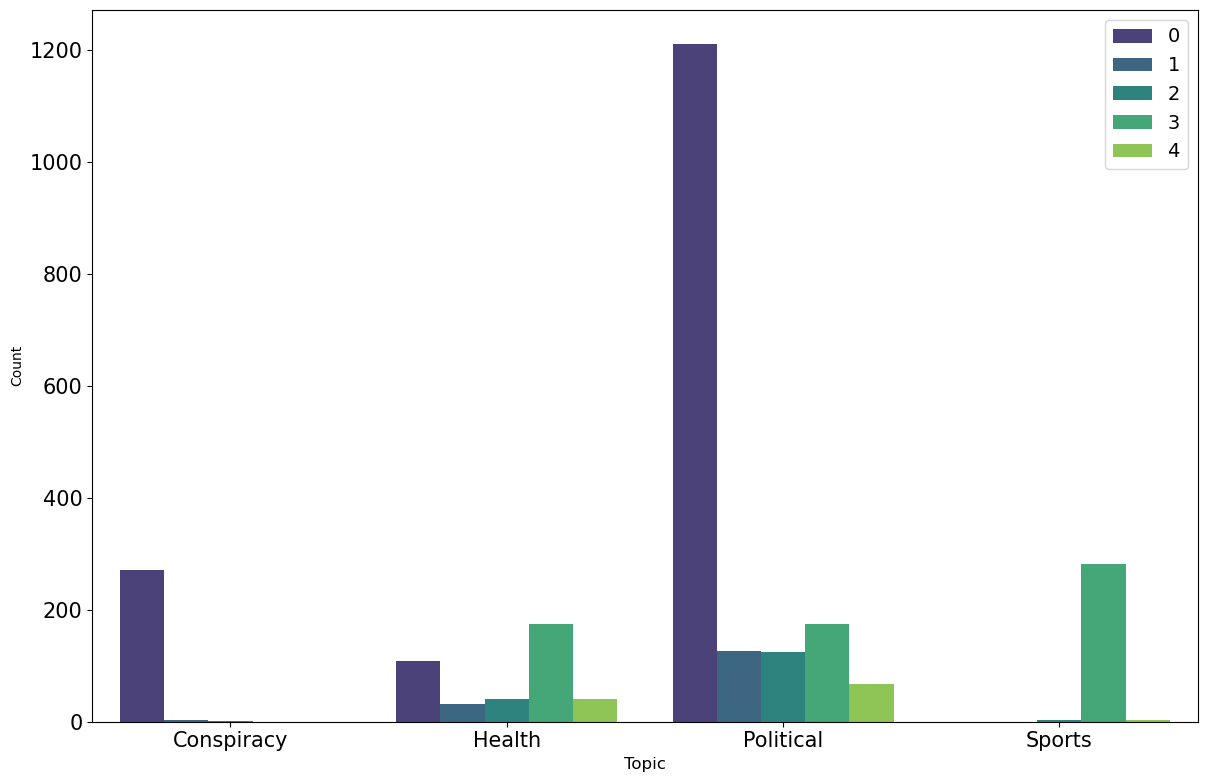

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Group by 'Topics' and 'label' and count how many newspapers are online for each combination
topic_label_counts = df.groupby(['Topics', 'label']).size().reset_index(name='Count')

# Modify the Topics column to display only the first few words (e.g., first 2 words)
topic_label_counts['ShortTopic'] = topic_label_counts['Topics'].apply(lambda x: ' '.join(x.split()[:1]))

# Plotting
plt.figure(figsize=(12, 8))
sns.barplot(x='ShortTopic', y='Count', hue='label', data=topic_label_counts, palette='viridis')

# Adding labels and title
plt.xticks(rotation=0, fontsize=20)
plt.xlabel('Topic', fontsize=12)
plt.tight_layout()

# Modify legend font size
plt.legend(fontsize=14)  # Increase the legend font size

# Modify numbers on the graph
plt.tick_params(axis='both', which='major', labelsize=15)  # Increase the font size of the axis numbers

# Show the plot
plt.show()



In [7]:
topic_label_counts

,Topics,label,Count,ShortTopic
0,Conspiracy theories or hoaxes,0,271,Conspiracy
1,Conspiracy theories or hoaxes,1,3,Conspiracy
2,Conspiracy theories or hoaxes,2,1,Conspiracy
3,Conspiracy theories or hoaxes,3,0,Conspiracy
4,Conspiracy theories or hoaxes,4,0,Conspiracy
5,Health or medical information,0,108,Health
6,Health or medical information,1,31,Health
7,Health or medical information,2,40,Health
8,Health or medical information,3,174,Health
9,Health or medical information,4,40,Health


In [8]:
pol = df[df['Topics'] == 'Political news or commentary']

pol

,Domain,Score,Country,Language,Topics,Paywall,Opinion/Advocacy Journalism,label
7,andersonreporter.com,32.0,US,en,Political news or commentary,No,Yes,0
8,amestoday.com,32.0,US,en,Political news or commentary,No,Yes,0
9,amarillogazette.com,32.0,US,en,Political news or commentary,No,Yes,0
10,altoonatimes.com,32.0,US,en,Political news or commentary,No,Yes,0
11,alohastatenews.com,32.0,US,en,Political news or commentary,No,Yes,0
...,...,...,...,...,...,...,...,...
9307,abendzeitung-muenchen.de,100.0,ALL,en,Political news or commentary,No,No,4
9309,freiepresse.de,100.0,ALL,en,Political news or commentary,No,No,4
9315,regenbogen.de,87.5,ALL,en,Political news or commentary,No,No,3
9317,rnd.de,92.5,ALL,en,Political news or commentary,No,No,3


## Removing rows with label zero which are too much

In [9]:
# Filter rows with label 0
df_label_0 = pol[pol['label'] == 0]

# Randomly sample 175 rows from label 0
df_label_0_sampled = df_label_0.sample(n=175, random_state=42)

# Keep all other labels
df_other_labels = pol[pol['label'] != 0]

# Combine the sampled label 0 rows with the rest of the dataset
df_final = pd.concat([df_label_0_sampled, df_other_labels])

# Shuffle the dataset (optional)
pol = df_final.sample(frac=1, random_state=42).reset_index(drop=True)

# Group by 'Topics' and 'label' and count how many newspapers are online for each combination
topic_label_counts = pol.groupby(['Topics', 'label']).size().reset_index(name='Count')

# Modify the Topics column to display only the first few words (e.g., first 2 words)
topic_label_counts['ShortTopic'] = topic_label_counts['Topics'].apply(lambda x: ' '.join(x.split()[:1]))

topic_label_counts


/tmp/ipykernel_1753204/4229100631.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  topic_label_counts = pol.groupby(['Topics', 'label']).size().reset_index(name='Count')


,Topics,label,Count,ShortTopic
0,Political news or commentary,0,175,Political
1,Political news or commentary,1,127,Political
2,Political news or commentary,2,124,Political
3,Political news or commentary,3,175,Political
4,Political news or commentary,4,68,Political


In [10]:
# Check NaN count per column
nan_counts = pol.isna().sum()
print("NaN values per column:")
print(nan_counts)

# Total rows with at least one NaN
total_nan_rows = pol.isna().any(axis=1).sum()
print(f"\nTotal rows with NaN values: {total_nan_rows}")

NaN values per column:
Domain                         0
Score                          0
Country                        0
Language                       0
Topics                         0
Paywall                        0
Opinion/Advocacy Journalism    5
label                          0
dtype: int64

Total rows with NaN values: 5


## Make the label appear one afther one

In [11]:
# Create a cycle counter within each label group
pol['cycle'] = pol.groupby('label').cumcount()

# Sort by cycle (to group iterations) and label (to order 0,1,2,3,4)
pol = pol.sort_values(by=['cycle', 'label'])

# Optional: Remove the temporary 'cycle' column
pol = pol.drop(columns='cycle')

/tmp/ipykernel_1753204/4172571022.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pol['cycle'] = pol.groupby('label').cumcount()


In [12]:
# Shuffle the entire dataframe
pol = pol.reset_index(drop=True)

pol

,Domain,Score,Country,Language,Topics,Paywall,Opinion/Advocacy Journalism,label
0,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
1,theguardiansofdemocracy.com,50.0,US,en,Political news or commentary,No,Yes,1
2,middlesborodailynews.com,72.5,US,en,Political news or commentary,No,No,2
3,tribunemag.co.uk,80.0,GB,en,Political news or commentary,No,Yes,3
4,nationalworld.com,100.0,GB,en,Political news or commentary,No,No,4
...,...,...,...,...,...,...,...,...
664,berliner-kurier.de,95.0,ALL,en,Political news or commentary,No,No,3
665,eaglevalleytimes.com,32.0,US,en,Political news or commentary,No,Yes,0
666,iowacapitaldispatch.com,87.5,US,en,Political news or commentary,No,No,3
667,petroplexnews.com,32.0,US,en,Political news or commentary,No,Yes,0


In [13]:
# Check NaN count per column
nan_counts = pol.isna().sum()
print("NaN values per column:")
print(nan_counts)

# Total rows with at least one NaN
total_nan_rows = pol.isna().any(axis=1).sum()
print(f"\nTotal rows with NaN values: {total_nan_rows}")



NaN values per column:
Domain                         0
Score                          0
Country                        0
Language                       0
Topics                         0
Paywall                        0
Opinion/Advocacy Journalism    5
label                          0
dtype: int64

Total rows with NaN values: 5


In [15]:
pol.to_csv('Dataset/startingPoliticsDomainInputOfScraping.csv')

## Scraper

In [ ]:
import os
import newspaper
import csv
import pandas as pd
import time
import logging
import signal
import hashlib
import requests
from newspaper.article import ArticleException  # For catching article download/parse errors

# ----------------------------
# Custom Exceptions & Timeout Setup
# ----------------------------
class TimeoutException(Exception):
    """Custom exception for handling timeouts during article processing."""
    pass

class ScrapingBlockedException(Exception):
    """Raised when the target website appears to be blocking scraping attempts."""
    pass

def timeout_handler(signum, frame):
    """Handler for the timeout signal. Raises a TimeoutException when triggered."""
    raise TimeoutException("Operation timed out")

# Set up the signal handler for timeouts
signal.signal(signal.SIGALRM, timeout_handler)

# Ensure the 'ScraperLogs' folder exists for storing logs
if not os.path.exists('ScraperLogs'):
    os.makedirs('ScraperLogs')

# Configure logging to save logs inside the 'ScraperLogs' folder
logging.basicConfig(filename='ScraperLogs/scraper.log', level=logging.INFO,
                    format='%(asctime)s - %(levelname)s - %(message)s')

# ----------------------------
# Helper Function: Compute MD5 Hash
# ----------------------------
def compute_hash(text):
    """Compute the MD5 hash of a given text string."""
    return hashlib.md5(text.encode('utf-8')).hexdigest()

# ----------------------------
# Robust Article Processing Function
# ----------------------------
def process_article(article, max_retries=3, timeout_seconds=30):
    """
    Downloads and parses an article with retries and timeout handling.
    Returns True if successful, False otherwise.
    """
    retries = 0
    while True:
        try:
            print(f"--> Processing article: {article.url}")
            signal.alarm(timeout_seconds)  # Set a timeout for the operation
            article.download()  # Download the article content
            article.parse()  # Parse the article content
            signal.alarm(0)  # Cancel the timeout
            print(f"--> Successfully processed article: {article.url}")
            return True
        except ArticleException as e:
            signal.alarm(0)  # Cancel the timeout
            error_msg = str(e).lower()
            # If we detect a 401, 403, or unauthorized error, skip immediately.
            if "401" in error_msg or "forbidden" in error_msg or "unauthorized" in error_msg:
                logging.error(f"Unauthorized/Forbidden for article {article.url}: {e}")
                print(f"!! Unauthorized/Forbidden error on article: {article.url}. Skipping article.")
                return False
            elif "incompleteread" in error_msg:
                logging.error(f"IncompleteRead error for article: {article.url} - {e}")
                print(f"!! IncompleteRead error on article: {article.url}. Waiting 60 seconds before retrying.")
                time.sleep(60)  # Wait before retrying
                retries += 1
            else:
                logging.error(f"ArticleException for article {article.url}: {e}")
                print(f"!! ArticleException on article: {article.url} - {e}. Skipping article.")
                return False
        except TimeoutException:
            signal.alarm(0)  # Cancel the timeout
            logging.error(f"Timeout processing article: {article.url}")
            print(f"!! Timeout on article: {article.url}. Skipping article.")
            return False
        except Exception as e:
            signal.alarm(0)  # Cancel the timeout
            error_msg = str(e).lower()
            # If error indicates blocking, skip the article immediately.
            if ("403" in error_msg or "forbidden" in error_msg or "blocked" in error_msg or
                "401" in error_msg or "unauthorized" in error_msg):
                logging.error(f"Scraping blocked for article {article.url}: {e}")
                print(f"!! Scraping blocked on article: {article.url}. Skipping article.")
                return False
            elif "connection" in error_msg or "timed out" in error_msg or "temporarily unavailable" in error_msg:
                logging.error(f"Connection error for article {article.url}: {e}")
                print(f"!! Connection error on article: {article.url}. Waiting 60 seconds before retrying.")
                time.sleep(60)  # Wait before retrying
                continue  # Do not count these errors toward retries.
            else:
                logging.error(f"Error processing article {article.url}: {e}")
                print(f"!! Error on article: {article.url} - {e}. Skipping article.")
                return False
        finally:
            signal.alarm(0)  # Ensure the timeout is always canceled
        if retries >= max_retries:
            print(f"!! Skipping article after {max_retries} retries: {article.url}")
            return False

# ----------------------------
# Resume/CSV Setup
# ----------------------------
output_file = 'Dataset/onlyPoliticsAutoScraping.csv'  # Output CSV file name
domain_hashes = {}  # Dictionary to store hashes of article texts by domain
domain_counts = {}  # Dictionary to store counts of articles by domain
start_index = 0  # Starting index in the DataFrame
csv_mode = 'w'  # File mode for CSV (write or append)
write_header = True  # Whether to write the header row in the CSV

# Assume your DataFrame 'pol' is already loaded with columns such as:
# ['Domain', 'Score', 'Country', 'Language', 'Topics', 'Paywall', 'Opinion/Advocacy Journalism', 'label']
# For example:
# pol = pd.read_csv('pol.csv')

# Check if the output CSV file already exists
if os.path.exists(output_file):
    try:
        existing_df = pd.read_csv(output_file)
        if not existing_df.empty:
            # Load existing article hashes and counts from the CSV
            for _, row in existing_df.iterrows():
                dom = row['domain']
                txt = row['text']
                h = compute_hash(txt)
                if dom in domain_hashes:
                    domain_hashes[dom].add(h)
                    domain_counts[dom] += 1
                else:
                    domain_hashes[dom] = {h}
                    domain_counts[dom] = 1
            # Determine the last processed domain and resume from there
            last_domain = existing_df.iloc[-1]['domain']
            if last_domain in pol['Domain'].values:
                start_index = pol[pol['Domain'] == last_domain].index[0]
                print(f"Resuming from domain '{last_domain}' at index {start_index} in your DataFrame.")
                logging.info(f"Resuming from domain '{last_domain}' at index {start_index}.")
            else:
                print("Last processed domain not found in DataFrame. Starting from the beginning.")
                logging.info("Last processed domain not found in DataFrame. Starting from the beginning.")
        csv_mode = 'a'  # Append to the existing CSV
        write_header = False  # Do not write the header again
    except Exception as e:
        print(f"Error loading existing CSV: {e}. Starting fresh.")
        logging.error(f"Error loading CSV: {e}")
else:
    print("No existing CSV found. Starting fresh scraping.")

# ----------------------------
# Main Scraping Loop with Robustness Features
# ----------------------------
with open(output_file, csv_mode, newline='', encoding='utf-8') as csvfile:
    fieldnames = ['url', 'title', 'text', 'authors',
                  'domain', 'score', 'country', 'language',
                  'topics', 'paywall', 'opinion_advocacy', 'label']
    writer = csv.DictWriter(csvfile, fieldnames=fieldnames)
    if write_header:
        writer.writeheader()  # Write the header row if needed

    # Iterate over the DataFrame starting from the resume point
    for idx, row in pol.iloc[start_index:].iterrows():
        domain = row['Domain']
        current_count = domain_counts.get(domain, 0)
        if current_count >= 200:
            print(f"*** Already scraped 200 articles for {domain}. Skipping this domain.")
            logging.info(f"Already scraped 200 articles for {domain}.")
            continue

        # Ensure the domain URL starts with 'https://'
        if not domain.startswith('http'):
            homepage_url = 'https://' + domain
        else:
            homepage_url = domain

        print(f"\n=== Processing domain: {homepage_url} ===")
        logging.info(f"Processing domain: {homepage_url}")

        # Build the newspaper source with robust network handling
        source = None
        while True:
            try:
                source = newspaper.build(homepage_url, memoize_articles=False, language='en')
                break  # Successfully built the source
            except Exception as e:
                error_msg = str(e).lower()
                if ("403" in error_msg or "forbidden" in error_msg or "blocked" in error_msg or
                    "401" in error_msg or "unauthorized" in error_msg):
                    print(f"!! Scraping blocked for {homepage_url}: {e}. Skipping this newspaper.")
                    logging.error(f"Scraping blocked for {homepage_url}: {e}")
                    source = None
                    break
                elif "connection" in error_msg or "timed out" in error_msg or "temporarily unavailable" in error_msg:
                    print(f"!! Connection error while building source for {homepage_url}: {e}")
                    logging.error(f"Connection error building source for {homepage_url}: {e}")
                    print("Waiting 60 seconds for connection to return...")
                    time.sleep(60)  # Wait before retrying
                    continue
                else:
                    print(f"!! Error building source for {homepage_url}: {e}")
                    logging.error(f"Error building source for {homepage_url}: {e}")
                    source = None
                    break
        if source is None:
            continue  # Skip to the next domain if source building failed

        print(f"Found {len(source.articles)} articles at {homepage_url}")
        logging.info(f"Found {len(source.articles)} articles at {homepage_url}")

        articles_saved = current_count
        try:
            for article in source.articles:
                if articles_saved >= 200:
                    print(f"*** Reached 200 articles for {domain}. Moving to next domain.")
                    logging.info(f"Reached 200 articles for {domain}.")
                    break

                if not article.url:
                    continue  # Skip articles without a valid URL

                try:
                    if process_article(article):
                        token_count = len(article.text.split())
                        if token_count <= 100:
                            print(f"--> Skipping article due to insufficient token count ({token_count} tokens): {article.title}")
                            continue  # Skip articles with too few tokens

                        article_hash = compute_hash(article.text)
                        if domain not in domain_hashes:
                            domain_hashes[domain] = set()

                        if article_hash in domain_hashes[domain]:
                            print(f"--> Duplicate article detected (hash match). Skipping: {article.title}")
                            continue  # Skip duplicate articles

                        # Save the article authors as a semicolon-separated string
                        authors = "; ".join(article.authors) if article.authors else ""

                        # Write the article data to the CSV
                        writer.writerow({
                            'url': article.url,
                            'title': article.title,
                            'text': article.text,
                            'authors': authors,
                            'domain': row['Domain'],
                            'score': row['Score'],
                            'country': row['Country'],
                            'language': row['Language'],
                            'topics': row['Topics'],
                            'paywall': row['Paywall'],
                            'opinion_advocacy': row['Opinion/Advocacy Journalism'],
                            'label': row['label']
                        })
                        domain_hashes[domain].add(article_hash)
                        articles_saved += 1
                        domain_counts[domain] = articles_saved
                        print(f"--> Saved article: {article.title} (Total for domain: {articles_saved})")
                    else:
                        print(f"--> Skipped article: {article.url}")
                except ScrapingBlockedException:
                    print(f"!! Scraping block detected for {domain} during article processing. Skipping this newspaper.")
                    logging.error(f"Scraping block detected for {domain} during article processing.")
                    break  # Move to the next domain
        except ScrapingBlockedException:
            continue  # Skip to the next domain if scraping is blocked

        print(f"=== Completed processing for domain: {domain}. Total articles saved for this domain: {articles_saved} ===")
        logging.info(f"Completed domain {domain} with {articles_saved} articles saved.")

No existing CSV found. Starting fresh scraping.

=== Processing domain: https://nemontananews.com ===
Found 46 articles at https://nemontananews.com
--> Processing article: https://nemontananews.com/stories/670532029-1-gas-station-in-cities-throughout-phillips-county-had-the-cheapest-regular-gas-in-week-ending-mar-15
--> Successfully processed article: https://nemontananews.com/stories/670532029-1-gas-station-in-cities-throughout-phillips-county-had-the-cheapest-regular-gas-in-week-ending-mar-15
--> Saved article: 1 gas station in cities throughout Phillips County had the cheapest regular gas in week ending Mar. 15 (Total for domain: 1)
--> Processing article: https://nemontananews.com/stories/670175501-mccone-county-income-maintenance-dependency-reached-1-3-in-2022
--> Successfully processed article: https://nemontananews.com/stories/670175501-mccone-county-income-maintenance-dependency-reached-1-3-in-2022
--> Saved article: McCone County: Income Maintenance dependency reached 1.3% in